In [1]:
!pip install -q nflreadpy pyarrow xgboost shap mlflow
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import mlflow
import shap
from sklearn.metrics import roc_auc_score

pbp = pd.read_parquet("/content/drive/MyDrive/pbp_2015_2025_day3.parquet")

df = pbp[(pbp["season_type"] == "REG") & pbp["posteam"].notna() & (pbp["result"] != 0)].copy()
df["home_win"] = (df["result"] > 0).astype(int)
df["home_lead"] = df["total_home_score"] - df["total_away_score"]
df["time_left"] = df["game_seconds_remaining"]
df["home_has_ball"] = (df["posteam"] == df["home_team"]).astype(float)
df["home_yards_to_score"] = np.where(df["home_has_ball"] == 1,
                                     df["yardline_100"], 100 - df["yardline_100"])
df["spread"] = df["spread_line"]
df["home_to"] = df["home_timeouts_remaining"]
df["away_to"] = df["away_timeouts_remaining"]
df["down"] = df["down"].fillna(0)
df["ydstogo"] = df["ydstogo"].fillna(0)
frac_left = (df["game_seconds_remaining"] / 3600).clip(0, 1)
df["lead_x_time"] = df["home_lead"] * (1 - frac_left)
df["spread_x_time"] = df["spread_line"] * frac_left

FEATURES = ["home_lead", "time_left", "home_has_ball", "home_yards_to_score",
            "spread", "home_to", "away_to", "down", "ydstogo",
            "lead_x_time", "spread_x_time"]
df = df.dropna(subset=FEATURES + ["home_win"])
print("clean:", df.shape)

clean: (471027, 27)


In [3]:
train = df[df["season"] <= 2021]
valid = df[df["season"] == 2022]
test  = df[df["season"] >= 2023]
Xtr, ytr = train[FEATURES], train["home_win"].to_numpy()
Xva, yva = valid[FEATURES], valid["home_win"].to_numpy()
Xte, yte = test[FEATURES],  test["home_win"].to_numpy()
print(len(train), len(valid), len(test))

def log_loss(y, p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def brier(y, p):
    return np.mean((p - y) ** 2)

296849 43367 130811


In [4]:
mlflow.set_tracking_uri("sqlite:////content/drive/MyDrive/mlflow.db")
mlflow.set_experiment("nfl-win-prob")

2026/11/07 21:37:08 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/07 21:37:09 INFO mlflow.store.db.utils: Updating database tables
2026/11/07 21:37:14 INFO mlflow.tracking.fluent: Experiment with name 'nfl-win-prob' does not exist. Creating a new experiment.


<Experiment: artifact_location='/content/mlruns/1', creation_time=1794087434885, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1794087434885, lifecycle_stage='active', name='nfl-win-prob', tags={}, trace_location=None, workspace='default'>

In [5]:
MONO = {"home_lead": 1, "spread": 1, "home_yards_to_score": -1,
        "lead_x_time": 1, "spread_x_time": 1}
mono = tuple(MONO.get(f, 0) for f in FEATURES)   # FEATURES order lo +1 / -1 / 0

results = {}
for name, cons in [("xgb_plain", None), ("xgb_monotonic", mono)]:
    params = dict(n_estimators=2000, learning_rate=0.03, max_depth=4,
                  subsample=0.8, colsample_bytree=0.8, min_child_weight=2000,
                  eval_metric="logloss", early_stopping_rounds=100)
    if cons:
        params["monotone_constraints"] = cons

    with mlflow.start_run(run_name=name):
        m = xgb.XGBClassifier(**params)
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
        p = m.predict_proba(Xte)[:, 1]
        res = dict(best_iteration=m.best_iteration,
                   test_log_loss=log_loss(yte, p),
                   test_brier=brier(yte, p),
                   test_auc=roc_auc_score(yte, p))
        mlflow.log_params({k: str(v) for k, v in params.items()})
        mlflow.log_metrics({k: float(v) for k, v in res.items()})
        results[name] = (m, p, res)
        print(name, {k: round(float(v), 4) for k, v in res.items()})

xgb_plain {'best_iteration': 117.0, 'test_log_loss': 0.4622, 'test_brier': 0.1523, 'test_auc': 0.8603}
xgb_monotonic {'best_iteration': 136.0, 'test_log_loss': 0.4618, 'test_brier': 0.1523, 'test_auc': 0.8603}


In [6]:
mask = test["vegas_home_wp"].notna().to_numpy()
print(f"{'model':28s} {'log loss':>9s}")
print(f"{'logistic regression (Day 4)':28s} {0.4541:9.4f}")
for name in results:
    print(f"{name:28s} {log_loss(yte[mask], results[name][1][mask]):9.4f}")
print(f"{'nflverse vegas_home_wp':28s} {log_loss(yte[mask], test['vegas_home_wp'].to_numpy()[mask]):9.4f}")

model                         log loss
logistic regression (Day 4)     0.4541
xgb_plain                       0.4622
xgb_monotonic                   0.4618
nflverse vegas_home_wp          0.4486


In [7]:
base = Xte.sample(5000, random_state=1).copy()
up = base.copy()
up["home_lead"] += 1                                                     # home team ki +1 point
up["lead_x_time"] = up["home_lead"] * (1 - (up["time_left"] / 3600).clip(0, 1))   # dependent feature kooda update

for name in results:
    m = results[name][0]
    lower = m.predict_proba(up)[:, 1] < m.predict_proba(base)[:, 1] - 1e-9
    print(f"{name:15s} plays where +1 lead LOWERED win prob: {lower.mean():.2%}")

xgb_plain       plays where +1 lead LOWERED win prob: 0.26%
xgb_monotonic   plays where +1 lead LOWERED win prob: 0.00%


win prob: 0.86


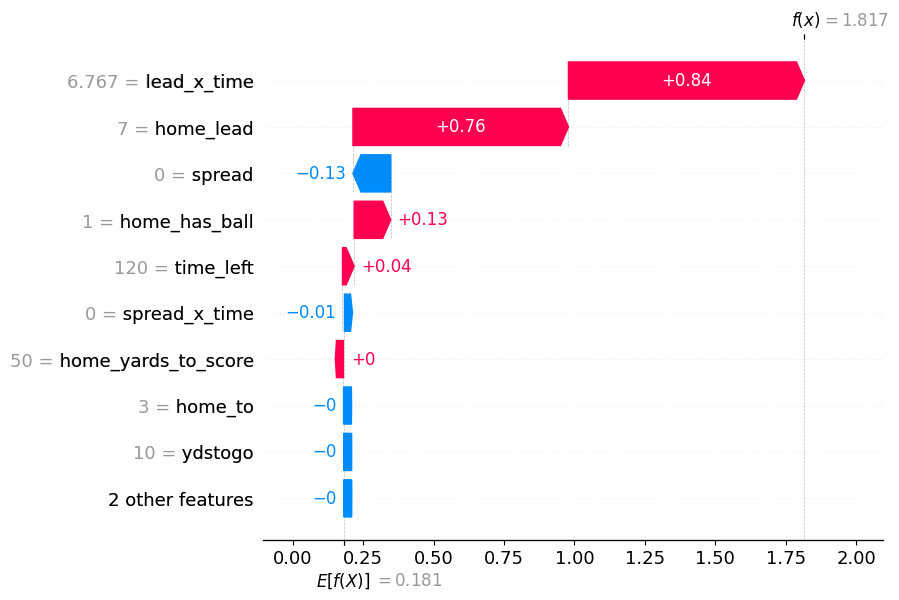

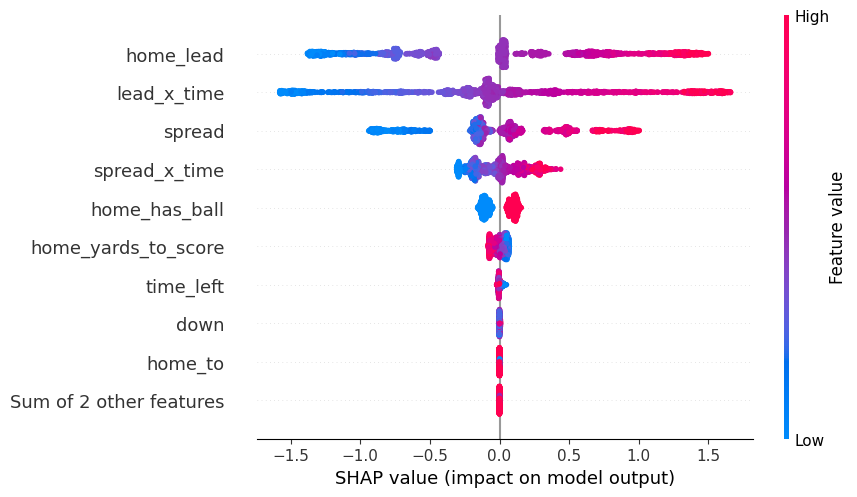

In [8]:
m = results["xgb_monotonic"][0]
explainer = shap.TreeExplainer(m)

# (a) one play: up 7, 2 min left, home ball at midfield, pick'em
def state(lead, secs, ball, yds, spread, hto=3, ato=3, down=1, ytg=10):
    f = secs / 3600
    return pd.DataFrame([[lead, secs, ball, yds, spread, hto, ato, down, ytg,
                          lead * (1 - f), spread * f]], columns=FEATURES)

one = state(7, 120, 1, 50, 0)
print("win prob:", round(float(m.predict_proba(one)[0, 1]), 3))
shap.plots.waterfall(explainer(one)[0])

# (b) whole model: 2000 test plays
sv = explainer(Xte.sample(2000, random_state=0))
shap.plots.beeswarm(sv)

In [9]:
runs = mlflow.search_runs()
print(runs[["tags.mlflow.runName", "params.max_depth", "params.min_child_weight",
            "metrics.best_iteration", "metrics.test_log_loss", "metrics.test_auc"]])

  tags.mlflow.runName params.max_depth params.min_child_weight  \
0       xgb_monotonic                4                    2000   
1           xgb_plain                4                    2000   

   metrics.best_iteration  metrics.test_log_loss  metrics.test_auc  
0                   136.0               0.461814          0.860266  
1                   117.0               0.462212          0.860272  


In [10]:
import json
from sklearn.linear_model import LogisticRegression

LR_FEATURES = ["home_lead", "time_left", "home_has_ball", "home_yards_to_score",
               "lead_x_time", "spread", "spread_x_time"]
tr_all = df[df["season"] <= 2022]                      # Day 4 laage: train 2015–2022
X = tr_all[LR_FEATURES].to_numpy(float)
mu, sd = X.mean(axis=0), X.std(axis=0)
lr = LogisticRegression(penalty=None, max_iter=3000).fit((X - mu) / sd, tr_all["home_win"])

p_lr = lr.predict_proba((test[LR_FEATURES].to_numpy(float) - mu) / sd)[:, 1]
print("logistic test log loss:", round(log_loss(yte, p_lr), 4))
print("weights:", dict(zip(LR_FEATURES, lr.coef_[0].round(3))))

model = {"features": LR_FEATURES, "mu": mu.tolist(), "sd": sd.tolist(),
         "w": lr.coef_[0].tolist(), "b": float(lr.intercept_[0])}
with open("/content/drive/MyDrive/wp_model.json", "w") as f:
    json.dump(model, f, indent=2)
print("saved wp_model.json")

logistic test log loss: 0.4541
weights: {'home_lead': np.float64(0.589), 'time_left': np.float64(-0.005), 'home_has_ball': np.float64(0.196), 'home_yards_to_score': np.float64(-0.129), 'lead_x_time': np.float64(1.627), 'spread': np.float64(0.478), 'spread_x_time': np.float64(0.266)}
saved wp_model.json
